# Lab 11 — Text visualization
Nauman Rafay · 24i-2558 · Section 5A

### Setup

In [1]:
# Install if needed: pip install pandas matplotlib scikit-learn nltk wordcloud vaderSentiment
# Open the notebook with Tweets.csv in the same folder.

from collections import Counter
from html import unescape
from pathlib import Path
import re
from tempfile import gettempdir

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from matplotlib.ticker import FuncFormatter
from nltk import pos_tag_sents
from nltk.corpus import wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud

base = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
tweets = pd.read_csv(base / "Tweets.csv")
text = tweets["text"].fillna("")
labels = ["negative", "neutral", "positive"]
negation = {"not", "no", "nor", "never", "neither", "cannot"}
stops = ENGLISH_STOP_WORDS - negation
names = {
    "united", "delta", "jetblue", "southwest", "southwestair", "americanair",
    "usairways", "virginamerica", "american", "virgin", "america", "usair",
}
url_or_handle = re.compile(r"https?://\S+|www\.\S+|(?<!\w)@\w+", re.I)
token_pattern = re.compile(r"[a-z]+(?:'[a-z]+)?")
repeat = re.compile(r"([a-z])\1{2,}")
text_repairs = {
    "cancelled flightled": "cancelled", "cancelled flighted": "cancelled",
    "flightled": "cancelled", "late flightr": "later",
    "reflight booking problems": "rebooking",
}
repair_pattern = re.compile(r"\b(?:" + "|".join(map(re.escape, text_repairs)) + r")\b")
vader = SentimentIntensityAnalyzer()


def naive_tokens(value):
    return re.findall(r"\b\w+\b", value.lower())


def expand_negation(value):
    value = value.replace("’", "'")
    value = re.sub(r"\bcan't\b", "can not", value)
    value = re.sub(r"\bwon't\b", "will not", value)
    return re.sub(r"n't\b", " not", value)


def clean_tokens(value, repair=False):
    value = expand_negation(url_or_handle.sub(" ", unescape(value).lower()))
    if repair:
        value = repair_pattern.sub(lambda match: text_repairs[match[0]], value)
    tokens = token_pattern.findall(value)
    return [repeat.sub(r"\1", token) if repeat.search(token) else token for token in tokens]


def counts(documents):
    return Counter(word for doc in documents for word in doc)


def scores(values):
    return pd.Series([vader.polarity_scores(v)["compound"] for v in values], index=values.index)


def classify(compound):
    return compound.map(lambda v: "positive" if v >= .05 else "negative" if v <= -.05 else "neutral")


def bars(ax, ranked, title, xlabel="Occurrences"):
    ranked = list(ranked)[::-1]
    ax.barh([term for term, _ in ranked], [n for _, n in ranked], color="#376878")
    ax.set(title=title, xlabel=xlabel)


def finish(fig):
    fig.tight_layout()
    plt.show()


nltk_cache = Path(gettempdir()) / "dav_lab11_nltk"
nltk.data.path.insert(0, str(nltk_cache))
for package in ("wordnet", "averaged_perceptron_tagger_eng"):
    nltk.download(package, download_dir=str(nltk_cache), quiet=True, raise_on_error=True)

## Part A — Prepare the tweets

### A1. Compare naive and cleaned tokens

In [2]:
examples = pd.Series([
    "@United This is sooooo bad 😡 #flightdelay https://t.co/example",
    "The flight was not good.", "No help from the agent.", "I can't recommend this.",
])
for value in examples:
    print(value, "\n  Naive:", naive_tokens(value), "\n  Clean:", clean_tokens(value))

# URLs and handles add fragments under naive tokenization. Remove them from word
# charts, retain hashtag text, compress stretched words, and expand n't to not.
# The English word charts omit emoji and punctuation. VADER receives original
# text so emphasis, emoji, capitalization and negation can affect its score.
naive = text.map(naive_tokens)
tokenized = text.map(clean_tokens)
clean = text.map(lambda value: clean_tokens(value, repair=True))

# Targeted repairs remove visible dataset substitutions such as "Flightled";
# the raw text is preserved for the VADER benchmark.

@United This is sooooo bad 😡 #flightdelay https://t.co/example 
  Naive: ['united', 'this', 'is', 'sooooo', 'bad', 'flightdelay', 'https', 't', 'co', 'example'] 
  Clean: ['this', 'is', 'so', 'bad', 'flightdelay']
The flight was not good. 
  Naive: ['the', 'flight', 'was', 'not', 'good'] 
  Clean: ['the', 'flight', 'was', 'not', 'good']
No help from the agent. 
  Naive: ['no', 'help', 'from', 'the', 'agent'] 
  Clean: ['no', 'help', 'from', 'the', 'agent']
I can't recommend this. 
  Naive: ['i', 'can', 't', 'recommend', 'this'] 
  Clean: ['i', 'can', 'not', 'recommend', 'this']


### A2. Test what happens when negation is removed

Negation ablation {'affected tweets': 4664, 'class changes': 1062, 'baseline subset accuracy': np.float64(0.48306174957118353), 'ablated subset accuracy': np.float64(0.36963979416809606)}
                original       negation removed  original score  ablated score
The flight was not good.  the flight was  good.         -0.3412         0.4404
 No help from the agent.   help from the agent.         -0.3089         0.4019
 I can't recommend this. i can  recommend this.         -0.2755         0.3612


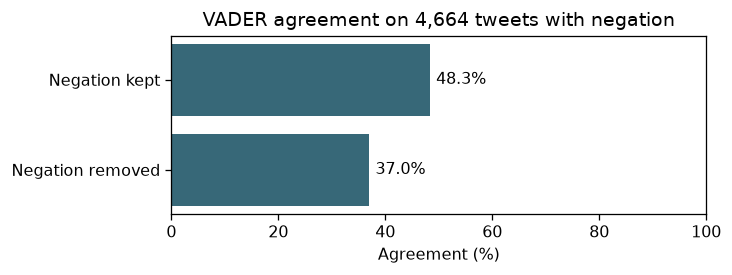

In [3]:
gold = tweets["airline_sentiment"]
negation_pattern = re.compile(r"\b(?:not|no|nor|never|neither|cannot)\b", re.I)
expanded = text.map(lambda value: expand_negation(value.lower()))
without_negation = expanded.str.replace(negation_pattern, "", regex=True)
compound = scores(text)
predicted = classify(compound)
has_negation = expanded.str.contains(negation_pattern)
baseline = classify(scores(expanded[has_negation]))
no_neg_prediction = classify(scores(without_negation[has_negation]))
print("Negation ablation", {
    "affected tweets": int(has_negation.sum()),
    "class changes": int(baseline.ne(no_neg_prediction).sum()),
    "baseline subset accuracy": baseline.eq(gold[has_negation]).mean(),
    "ablated subset accuracy": no_neg_prediction.eq(gold[has_negation]).mean(),
})
sentences = examples.iloc[1:]
ablated_sentences = sentences.map(lambda value: expand_negation(value.lower())).str.replace(negation_pattern, "", regex=True)
print(pd.DataFrame({"original": sentences, "negation removed": ablated_sentences,
                    "original score": scores(sentences), "ablated score": scores(ablated_sentences)}).to_string(index=False))

# A. Keep not, no, nor and related negators in the final stop list exception.
# Removing them makes "not good" positive and changes 1,062 predictions among
# 4,664 affected tweets. Agreement there drops from 48.3% to 37.0%.

agreement = pd.Series({
    "Negation kept": baseline.eq(gold[has_negation]).mean() * 100,
    "Negation removed": no_neg_prediction.eq(gold[has_negation]).mean() * 100,
})
fig, ax = plt.subplots(figsize=(6.5, 2.5))
bars(ax, agreement.items(), "VADER agreement on 4,664 tweets with negation", "Agreement (%)")
ax.set_xlim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)
finish(fig)

### A3. Compare stemming and lemmatization

cancelled cancel cancel
delayed delay delay
better better good
boarding board board
united unit united


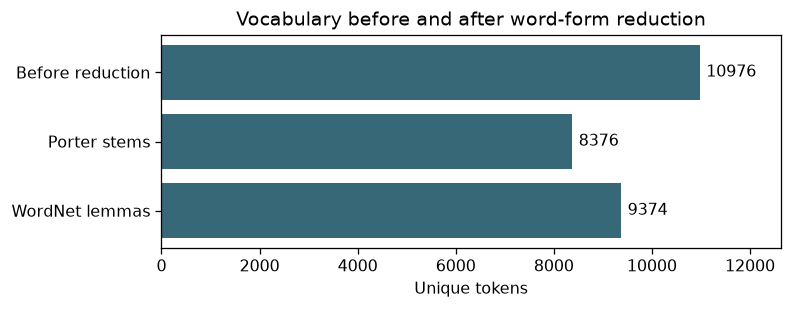

In [4]:
keep_negation = clean.map(lambda doc: [w for w in doc if w not in stops])
filtered = keep_negation.map(lambda doc: [w for w in doc if w not in names])
stemmer, lemmatizer = PorterStemmer(), WordNetLemmatizer()
pos_map = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}
tagged = pos_tag_sents(clean)
lemmas = [
    [lemmatizer.lemmatize(word, pos_map.get(tag[0], wordnet.NOUN))
     for word, tag in doc if word not in stops and word not in names]
    for doc in tagged
]
stems = [[stemmer.stem(w) for w in doc] for doc in filtered]

for word, pos in [("cancelled", "v"), ("delayed", "v"), ("better", "a"),
                  ("boarding", "v"), ("united", "a")]:
    print(word, stemmer.stem(word), lemmatizer.lemmatize(word, pos))

# Use POS-aware lemmatization. Both methods collapse cancelled to cancel,
# but stemming can turn united into unit, and lemmatization links better to good.

fig, ax = plt.subplots(figsize=(7, 2.8))
bars(ax, [(label, len(counts(data))) for label, data in [
    ("Before reduction", filtered), ("Porter stems", stems), ("WordNet lemmas", lemmas)
]], "Vocabulary before and after word-form reduction", "Unique tokens")
ax.bar_label(ax.containers[0], fmt="%d", padding=4)
ax.margins(x=.15)
finish(fig)

### A4. Measure the cost of cleaning

                       Vocabulary  Mean tokens  Empty tweets
Stage                                                       
Naive                       15089        18.35             0
Tokenized                   11264        16.18             0
Repaired                    11265        16.11             0
Stop words removed          10988         8.25            45
Airline names removed       10976         8.20            45
Lemmatized                   9374         8.20            45


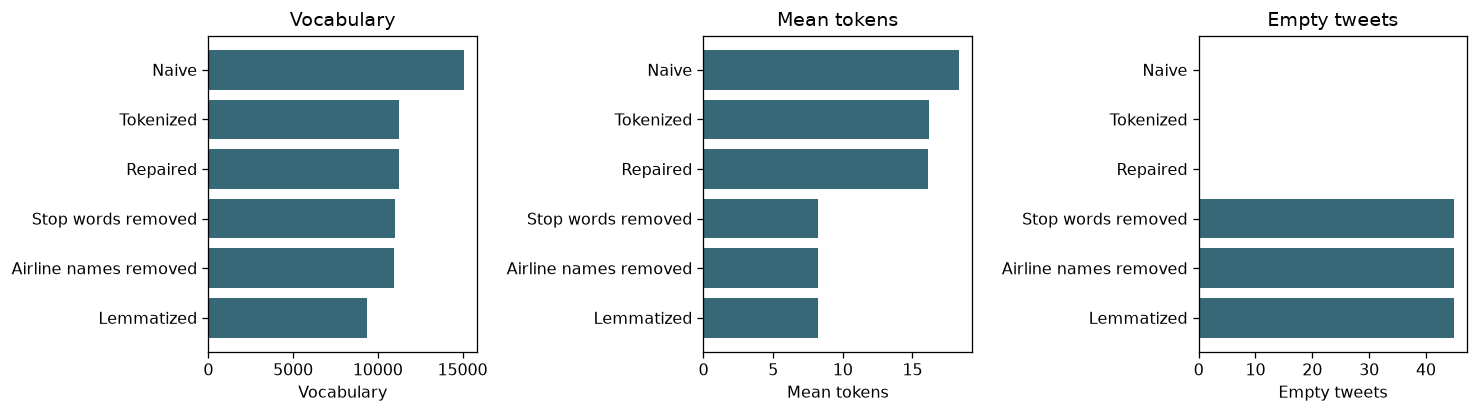

In [5]:
stages = [("Naive", naive), ("Tokenized", tokenized), ("Repaired", clean),
          ("Stop words removed", keep_negation), ("Airline names removed", filtered), ("Lemmatized", lemmas)]
summary = []
for stage, documents in stages:
    lengths = pd.Series([len(doc) for doc in documents])
    summary.append((stage, len(counts(documents)), lengths.mean(), lengths.eq(0).sum()))
cleaning = pd.DataFrame(summary, columns=["Stage", "Vocabulary", "Mean tokens", "Empty tweets"]).set_index("Stage")
print(cleaning.round(2).to_string())
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, metric in zip(axes, cleaning):
    bars(ax, cleaning[metric].items(), metric, metric)
finish(fig)

# The largest length loss occurs at stop-word removal, from about 16 to 8 tokens.
# It empties 45 of 14,640 tweets. This is acceptable for aggregate word charts.
# Keep all tweets for sentiment scoring and preserve original wording for review.

## Part B — Compare words and phrases

### B1. Show raw versus cleaned word frequencies

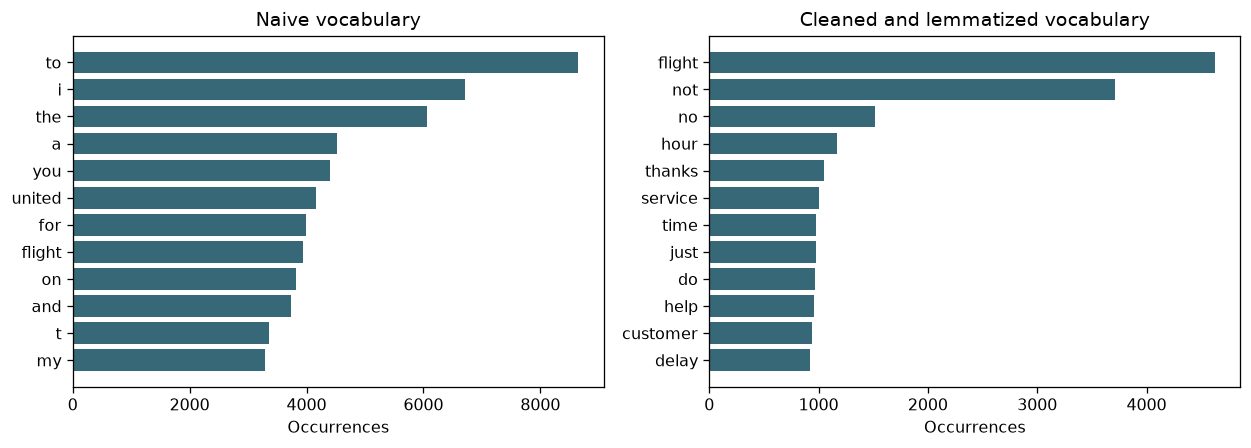

In [6]:
negative = gold.eq("negative")
positive = gold.eq("positive")
negative_words = counts(doc for doc, flag in zip(lemmas, negative) if flag)
positive_words = counts(doc for doc, flag in zip(lemmas, positive) if flag)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars(axes[0], counts(naive).most_common(12), "Naive vocabulary")
bars(axes[1], counts(lemmas).most_common(12), "Cleaned and lemmatized vocabulary")
finish(fig)

# B. Airline handles and generic filler crowd the naive chart. Their frequency is consistent with
# a corpus collected around named airline accounts, so it cannot measure brand
# recall or relative passenger volume.

### B2. Find terms associated with each sentiment

Shared top 20 words: ['customer', 'do', 'flight', 'get', 'help', 'just', 'not', 'service', 'time']
TF-IDF difference: ['thank', 'thanks', 'great', 'love', 'awesome', 'best', 'appreciate', 'good'] ['not', 'hour', 'flight', 'no', 'hold', 'delay', 'cancel', 'bag']


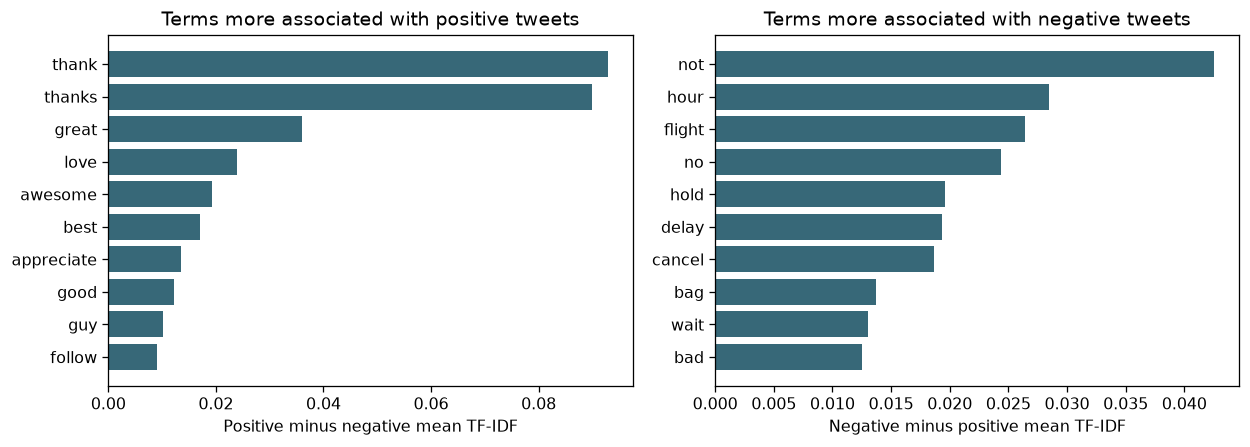

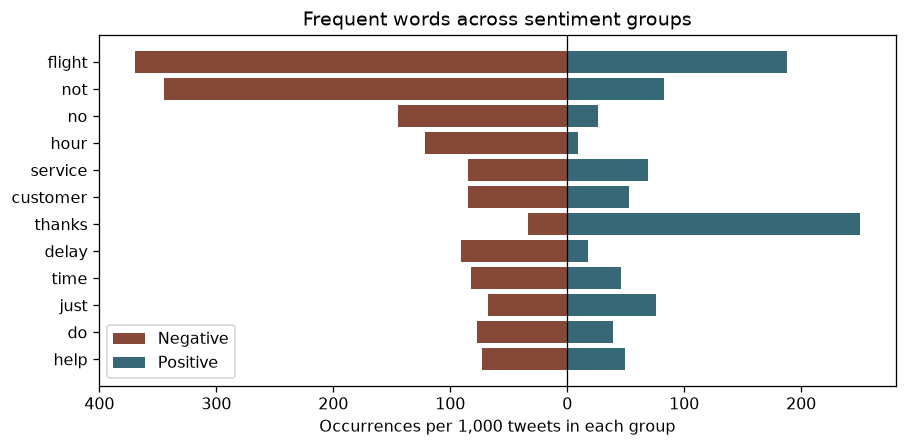

In [7]:
print("Shared top 20 words:", sorted(set(dict(negative_words.most_common(20))) &
                                     set(dict(positive_words.most_common(20)))))

docs = [" ".join(doc) for doc in lemmas]
vectorizer = TfidfVectorizer(min_df=10)
matrix = vectorizer.fit_transform(docs)
terms = vectorizer.get_feature_names_out()
polarity = pd.DataFrame({
    "Positive": matrix[positive.to_numpy()].mean(axis=0).A1,
    "Negative": matrix[negative.to_numpy()].mean(axis=0).A1,
}, index=terms)
difference = polarity["Positive"] - polarity["Negative"]
print("TF-IDF difference:", difference.nlargest(8).index.tolist(), difference.nsmallest(8).index.tolist())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bars(axes[0], list(difference.nlargest(10).items()), "Terms more associated with positive tweets", "Positive minus negative mean TF-IDF")
bars(axes[1], list((-difference).nlargest(10).items()), "Terms more associated with negative tweets", "Negative minus positive mean TF-IDF")
finish(fig)

shared = (negative_words + positive_words).most_common(12)
words = [pair[0] for pair in shared][::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(words, [-1000 * negative_words[w] / negative.sum() for w in words], color="#864937", label="Negative")
ax.barh(words, [1000 * positive_words[w] / positive.sum() for w in words], color="#376878", label="Positive")
ax.axvline(0, color="black", linewidth=.8)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(v):g}"))
ax.set(title="Frequent words across sentiment groups", xlabel="Occurrences per 1,000 tweets in each group")
ax.legend()
finish(fig)

# Flight, service and help occur frequently in both groups. Differences in mean
# TF-IDF highlight praise such as thanks, great and love, and complaints using
# hour, hold, delay and bag. A separate group average avoids favoring the
# larger negative group just because it has more tweets.

# In this chart, "flight" marks association with negative-labeled tweets.
# The surrounding phrase supplies the sentiment, as in "cancelled flight".

### B3. Find operational phrases and negation

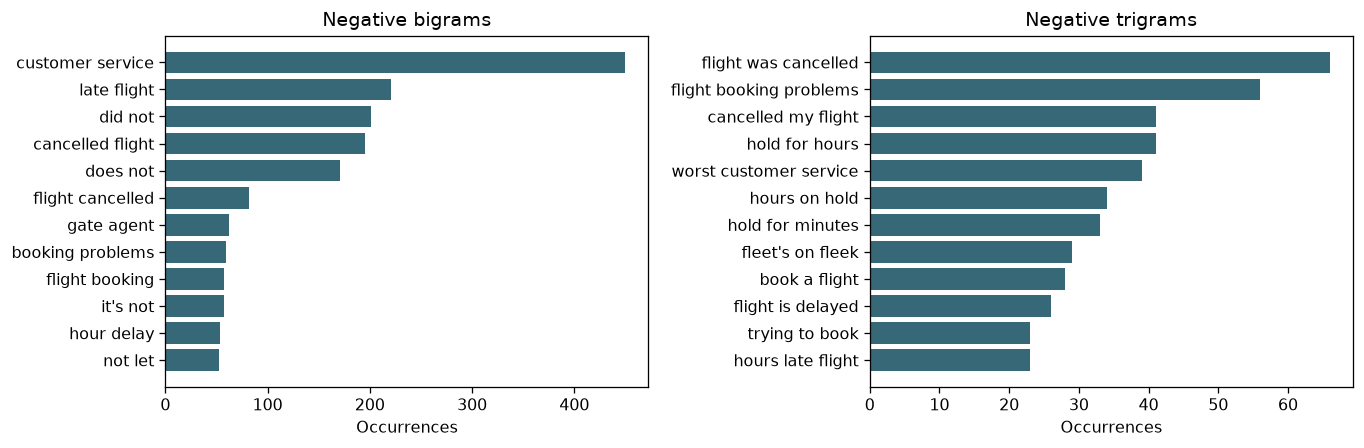

Phrase counts: {'cancelled flight': 195, 'customer service': 450, 'not happy': 23, 'hold time': 7} hold for hours: 41
Top phrases: [('customer service', 450), ('late flight', 221), ('did not', 201), ('cancelled flight', 195), ('does not', 171), ('flight cancelled', 82), ('gate agent', 62), ('booking problems', 59), ('flight booking', 57), ("it's not", 57), ('hour delay', 53), ('not let', 52)] [('flight was cancelled', 66), ('flight booking problems', 56), ('cancelled my flight', 41), ('hold for hours', 41), ('worst customer service', 39), ('hours on hold', 34), ('hold for minutes', 33), ("fleet's on fleek", 29), ('book a flight', 28), ('flight is delayed', 26), ('trying to book', 23), ('hours late flight', 23)]


In [8]:
def phrases(n):
    result = Counter()
    for doc in clean[negative]:
        for seq in zip(*(doc[i:] for i in range(n))):
            if seq[0] in stops or seq[-1] in stops or any(w in names for w in seq):
                continue
            result[" ".join(seq)] += 1
    return result


bigram, trigram = phrases(2), phrases(3)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars(axes[0], bigram.most_common(12), "Negative bigrams")
bars(axes[1], trigram.most_common(12), "Negative trigrams")
finish(fig)
print("Phrase counts:", {p: bigram[p] for p in ["cancelled flight", "customer service", "not happy", "hold time"]},
      "hold for hours:", trigram["hold for hours"])
print("Top phrases:", bigram.most_common(12), trigram.most_common(12))

# "Cancelled flight" isolates disrupted departures, and "hold for hours"
# points to support queues. "Not happy" reverses the positive meaning of happy.

### B4. Compare the negative word cloud and bar chart

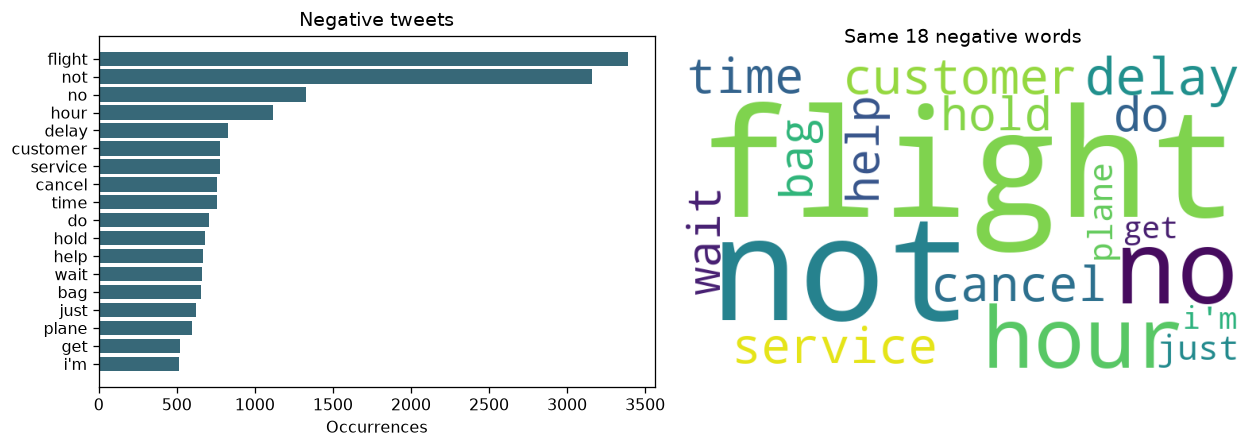

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
common_negative = negative_words.most_common(18)
bars(axes[0], common_negative, "Negative tweets")
cloud = WordCloud(width=700, height=400, background_color="white", random_state=24)
axes[1].imshow(cloud.generate_from_frequencies(dict(common_negative)))
axes[1].set_title("Same 18 negative words")
axes[1].axis("off")
finish(fig)

# Show the Director the bar chart. A common zero and count scale let the reader
# compare terms. The cloud makes a quick overview but font size and placement
# do not support precise comparisons.

## Part C — Evaluate VADER

### C1. Compare VADER with human labels

              precision    recall  f1-score   support

    negative      0.903     0.439     0.591      9178
     neutral      0.386     0.319     0.349      3099
    positive      0.282     0.910     0.431      2363

    accuracy                          0.490     14640
   macro avg      0.524     0.556     0.457     14640
weighted avg      0.694     0.490     0.514     14640



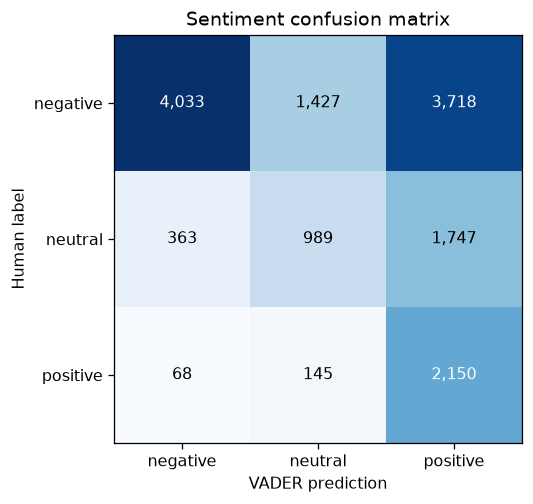

In [10]:
print(classification_report(gold, predicted, labels=labels, digits=3))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
cm = confusion_matrix(gold, predicted, labels=labels)
ax.imshow(cm, cmap="Blues")
ax.set(xticks=range(3), yticks=range(3), xticklabels=labels, yticklabels=labels,
       xlabel="VADER prediction", ylabel="Human label", title="Sentiment confusion matrix")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
finish(fig)

# C. Overall agreement is 49.0%, below the 62.7% majority-negative baseline.
# Neutral is hardest by recall (31.9%) and F1 (0.349). Positive recall is 91.0%
# but positive precision is 28.2%, and 3,718 negative tweets are called positive.

### C2. Audit strong disagreements

          tweet_id                                                                                                                                           text airline_sentiment  compound   primary cause
568466642193104897      @SouthwestAir Report was filed but would like to support some active searching.  Feels pretty passive now.  Info on computer is precious.          negative    0.9716 Airline context
569715860241129472                                                                       @AmericanAir that luggage you forgot...#mia.....he just won an oscar😄💝💝💝          negative    0.9712         Sarcasm
568862914154770432       @united MIA-EWR #384 😄😄😄 excellent crew. EWR-IAD #3589 😡😡😡 No crew to load bags - waiting w/ door open freezing. 20 mins past departure.          negative    0.9607  Mixed feelings
569208751972065280           @united What a really GREAT &amp; FLATTERING story about you! You should be very proud :) http://t.co/oKtUkjY92O (via @ParachuteGuy)          negat

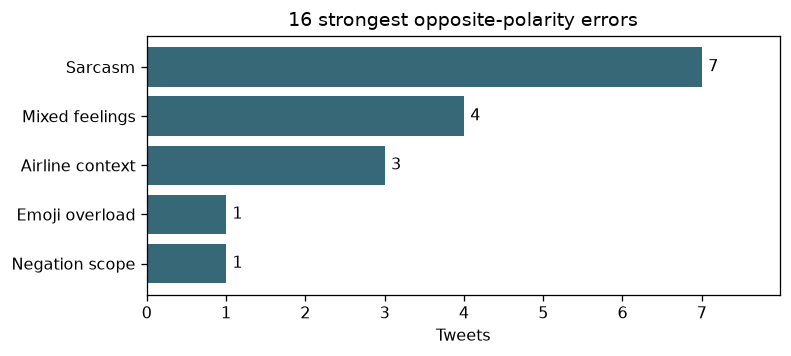

In [11]:
# Opposite-polarity errors with strongest VADER confidence, using high-confidence
# human labels to make the audit less sensitive to disputed examples.
opposite = (negative & predicted.eq("positive")) | (positive & predicted.eq("negative"))
audit = tweets.loc[opposite & tweets["airline_sentiment_confidence"].ge(.9),
                   ["tweet_id", "text", "airline_sentiment"]].copy()
audit["compound"] = compound.loc[audit.index]
audit = audit.sort_values(["compound", "tweet_id"], key=lambda s: s.abs() if s.name == "compound" else s,
                          ascending=[False, True]).head(16)
causes = {
    568466642193104897: "Airline context", 569715860241129472: "Sarcasm",
    568862914154770432: "Mixed feelings", 569208751972065280: "Sarcasm",
    568934749571387392: "Sarcasm", 567805465854488579: "Emoji overload",
    569514001450672128: "Sarcasm", 569835633147056128: "Mixed feelings",
    569215779830280192: "Airline context", 569630987858132992: "Negation scope",
    569249933271965696: "Mixed feelings", 569698504467021824: "Sarcasm",
    567755768037130241: "Mixed feelings", 568769373122342912: "Sarcasm",
    568800389903962112: "Sarcasm", 569162600237236224: "Airline context",
}
audit["primary cause"] = audit["tweet_id"].map(causes).fillna("Needs manual review")
print(audit.to_string(index=False))
print(audit["primary cause"].value_counts().to_string())

# Sarcasm is the largest category in the 16 manually reviewed extreme errors
# (7 of 16). This purposive sample does not estimate the overall error mix.
# Flag positive language near delays, long waits or cancellations for review.

fig, ax = plt.subplots(figsize=(7, 3.2))
bars(ax, audit["primary cause"].value_counts().items(), "16 strongest opposite-polarity errors", "Tweets")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.bar_label(ax.containers[0], padding=4)
ax.margins(x=.14)
finish(fig)

### C3. Test three invented tweets

In [12]:
constructed = pd.Series([
    "Amazing, fantastic, wonderful service. I only waited six hours on hold.",
    "The agent was good, which hardly makes up for being stranded overnight.",
    "Our flight was 6 hours late.",
])
print(pd.DataFrame({"tweet": constructed, "compound": scores(constructed),
                    "VADER": classify(scores(constructed))}).to_string(index=False))

# The first invented tweet scores +0.9022 because exaggerated praise wins over
# the hold complaint. The second scores +0.4404 because agent praise outweighs
# being stranded overnight. Six hours late scores 0.0000 even though the delay
# clearly conveys a problem. Detect complaint events alongside sentiment.

                                                                  tweet  compound    VADER
Amazing, fantastic, wonderful service. I only waited six hours on hold.    0.9022 positive
The agent was good, which hardly makes up for being stranded overnight.    0.4404 positive
                                           Our flight was 6 hours late.    0.0000  neutral


### C4. Check high-confidence human labels

High-confidence labels (n=10,458)
              precision    recall  f1-score   support

    negative      0.947     0.481     0.638      7391
     neutral      0.337     0.368     0.352      1550
    positive      0.286     0.943     0.438      1517

    accuracy                          0.531     10458
   macro avg      0.523     0.598     0.476     10458
weighted avg      0.761     0.531     0.567     10458

[[3554 1065 2772]
 [ 171  571  808]
 [  26   60 1431]]


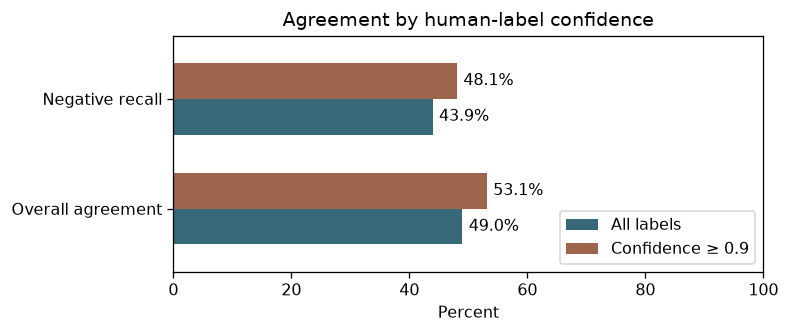

In [13]:
high_confidence = tweets["airline_sentiment_confidence"].ge(.9)
print(f"High-confidence labels (n={high_confidence.sum():,})")
print(classification_report(gold[high_confidence], predicted[high_confidence], labels=labels, digits=3))
print(confusion_matrix(gold[high_confidence], predicted[high_confidence], labels=labels))
comparison = pd.DataFrame({
    "All labels": [predicted.eq(gold).mean(), cm[0, 0] / cm[0].sum()],
    "Confidence ≥ 0.9": [predicted[high_confidence].eq(gold[high_confidence]).mean(),
                         predicted[high_confidence & negative].eq("negative").mean()],
}, index=["Overall agreement", "Negative recall"]) * 100
fig, ax = plt.subplots(figsize=(7, 3))
comparison.plot.barh(ax=ax, color=["#376878", "#9d654c"], width=.65)
ax.set(title="Agreement by human-label confidence", xlabel="Percent", xlim=(0, 100))
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=4)
ax.legend(loc="lower right")
finish(fig)

# High-confidence labels raise agreement to 53.1%; negative recall still reaches
# only 48.1%. The subset also has a different class mix, so the gain cannot be
# attributed entirely to cleaner labels.

## Part D — Compare airlines and plan triage

### D1. Compare customer service and operations complaints

Reason shares and counts:
 negativereason  Bad Flight  Can't Tell  Cancelled Flight  Customer Service Issue  Damaged Luggage  Flight Attendant Complaints  Flight Booking Problems  Late Flight  Lost Luggage  longlines
airline                                                                                                                                                                                      
American             0.044       0.101             0.126                   0.392            0.006                        0.044                    0.066        0.127         0.076      0.017
Delta                0.067       0.195             0.053                   0.208            0.012                        0.063                    0.046        0.282         0.060      0.015
Southwest            0.076       0.134             0.137                   0.330            0.012                        0.032                    0.051        0.128         0.076      0.024
US Airways           0.

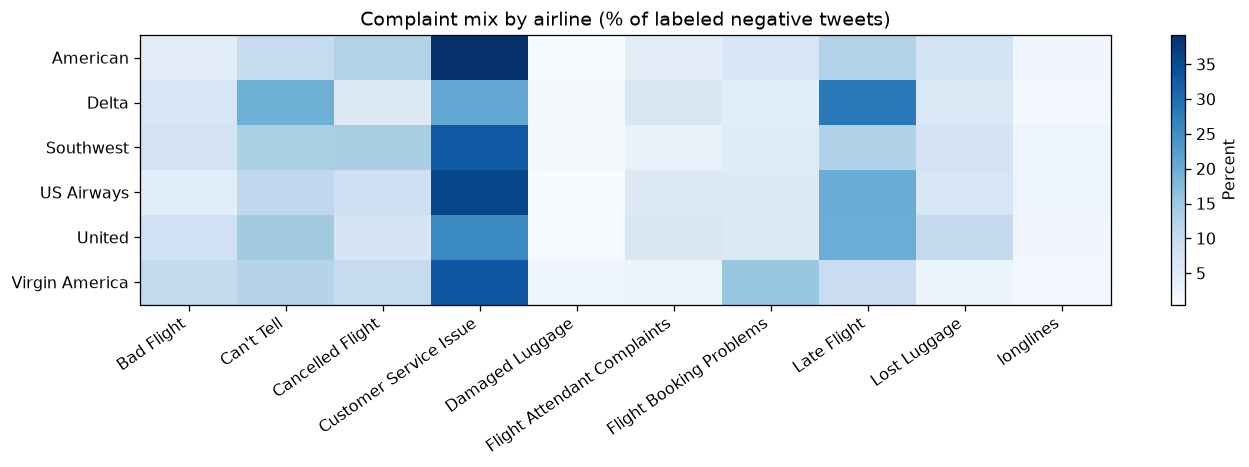

In [14]:
reasons = pd.crosstab(tweets.loc[negative, "airline"], tweets.loc[negative, "negativereason"])
reason_shares = reasons.div(reasons.sum(axis=1), axis=0)

print("Reason shares and counts:\n", reason_shares.round(3).to_string(), "\n", reasons.to_string())

operations = ["Late Flight", "Cancelled Flight", "Flight Booking Problems", "Lost Luggage"]
print("Service and operations shares:\n", pd.DataFrame({
    "Service": reason_shares["Customer Service Issue"],
    "Operations": reason_shares[operations].sum(axis=1),
}).round(3))

fig, ax = plt.subplots(figsize=(12, 4.2))
im = ax.imshow(reason_shares * 100, cmap="Blues", aspect="auto")
ax.set(yticks=range(len(reasons)), yticklabels=reasons.index,
       xticks=range(len(reasons.columns)), xticklabels=reasons.columns,
       title="Complaint mix by airline (% of labeled negative tweets)")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.colorbar(im, ax=ax, label="Percent")
finish(fig)

# D. American has the largest customer service share (39.2%). Delta has the
# largest share for the four specified operational categories (44.1%), with
# late flights alone at 28.2% of its negatives. These are complaint mixes.

### D2. Compare sentiment counts and shares

Airline counts:
 airline_sentiment  negative  neutral  positive
airline                                       
American               1960      463       336
Delta                   955      723       544
Southwest              1186      664       570
US Airways             2263      381       269
United                 2633      697       492
Virgin America          181      171       152 
Airline shares:
 airline_sentiment  negative  neutral  positive
airline                                       
American              0.710    0.168     0.122
Delta                 0.430    0.325     0.245
Southwest             0.490    0.274     0.236
US Airways            0.777    0.131     0.092
United                0.689    0.182     0.129
Virgin America        0.359    0.339     0.302


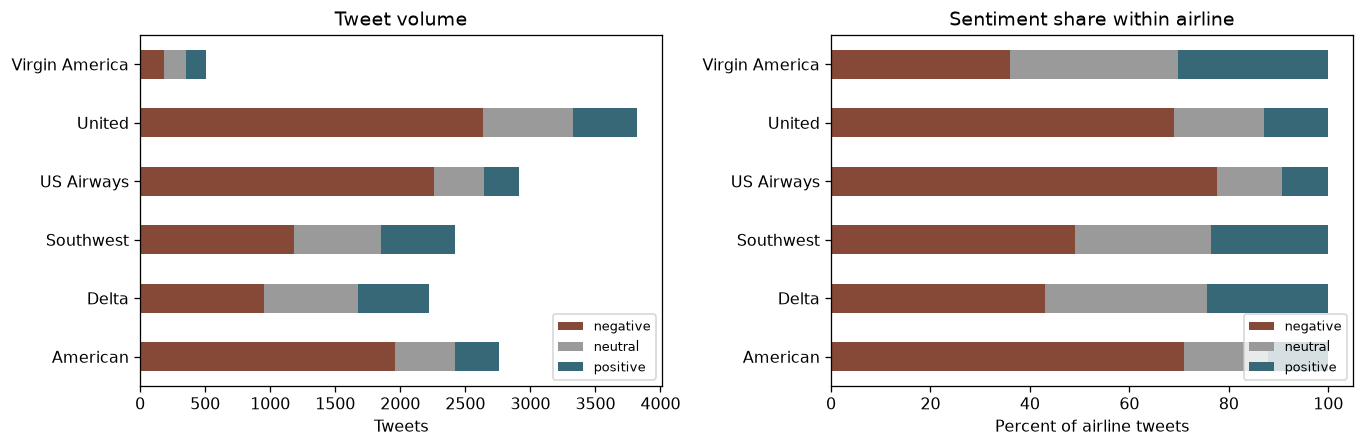

In [15]:
airlines = pd.crosstab(tweets["airline"], gold).reindex(columns=labels)
shares = airlines.div(airlines.sum(axis=1), axis=0)

print("Airline counts:\n", airlines, "\nAirline shares:\n", shares.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#864937", "#9a9a9a", "#376878"]
for ax, data, title in [(axes[0], airlines, "Tweet volume"), (axes[1], shares * 100, "Sentiment share within airline")]:
    data.plot.barh(stacked=True, ax=ax, color=colors, title=title)
    ax.set(xlabel="Tweets" if ax is axes[0] else "Percent of airline tweets", ylabel="")
    ax.legend(loc="lower right", fontsize=8)
finish(fig)

# United has the most negative posts (2,633), but US Airways has the highest
# negative share (77.7% vs. United's 68.9%). Report share for comparison and
# retain raw counts for workload planning.

### D3. Find spikes in negative tweets

Daily volume and negative share (Pacific time):
              sum  size      mean
date                            
2015-02-16     3     4  0.750000
2015-02-17   838  1408  0.595170
2015-02-18   736  1344  0.547619
2015-02-19   751  1376  0.545785
2015-02-20   835  1500  0.556667
2015-02-21  1049  1557  0.673732
2015-02-22  2266  3079  0.735953
2015-02-23  1919  3028  0.633752
2015-02-24   781  1344  0.581101


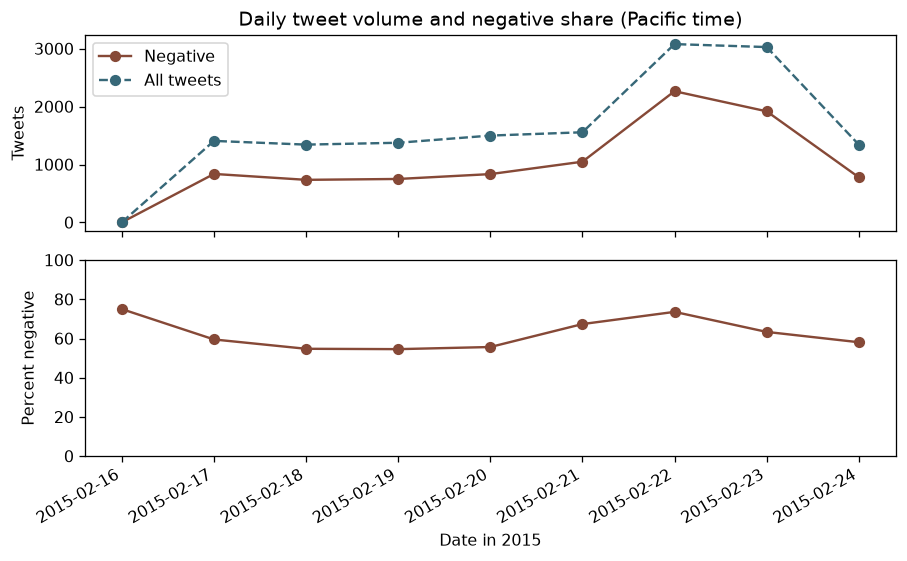

In [16]:
created = pd.to_datetime(tweets["tweet_created"], utc=True)
day = created.dt.tz_convert("America/Los_Angeles").dt.date
daily = pd.DataFrame({"date": day, "negative": negative}).groupby("date")["negative"].agg(["sum", "size", "mean"])
print("Daily volume and negative share (Pacific time):\n", daily.to_string())
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
axes[0].plot(daily.index, daily["sum"], "o-", label="Negative", color="#864937")
axes[0].plot(daily.index, daily["size"], "o--", label="All tweets", color="#376878")
axes[0].set(ylabel="Tweets", title="Daily tweet volume and negative share (Pacific time)")
axes[0].legend()
axes[1].plot(daily.index, daily["mean"] * 100, "o-", color="#864937")
axes[1].set(ylabel="Percent negative", xlabel="Date in 2015", ylim=(0, 100))
fig.autofmt_xdate()
finish(fig)

# Feb 22 had 2,266 negative tweets out of 3,079 (73.6%). Feb 23 had almost as
# many total tweets but a lower negative share (63.4%). Feb 16 has only four
# observations. The short window and lack of flight records rule out assigning
# a cause or interpreting this as a recurring weekly pattern.

### D4. Create a priority queue

Priority queue tiers:
 urgent
False    7528
True     1650


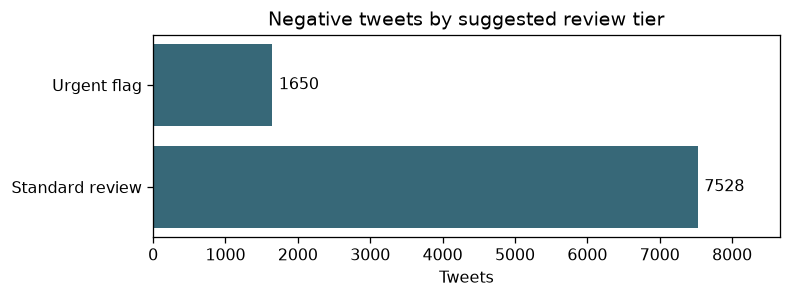

In [17]:
# Example queue preview. Include urgent issues even when the assigned reason is
# generic, and use oldest-first within each tier.
urgent_text = text.str.contains(r"\b(?:stranded|wheelchair|medical|unsafe|emergency)\b", case=False)
urgent_reason = tweets["negativereason"].isin(["Cancelled Flight", "Lost Luggage"])
queue = tweets.loc[negative, ["tweet_id", "airline", "negativereason"]].assign(
    urgent=(urgent_text | urgent_reason)[negative], created=created[negative]
)
queue = queue.sort_values(["urgent", "created", "tweet_id"], ascending=[False, True, True])
print("Priority queue tiers:\n", queue["urgent"].value_counts().to_string())

# Triage cancellations and lost bags, and flag possible accessibility, safety
# and stranded-traveler cases for human review. Work oldest first within each
# tier. This prioritizes time-sensitive passenger harm over retweet popularity.

fig, ax = plt.subplots(figsize=(7, 2.7))
bars(ax, [("Urgent flag", queue["urgent"].sum()), ("Standard review", (~queue["urgent"]).sum())],
     "Negative tweets by suggested review tier", "Tweets")
ax.bar_label(ax.containers[0], fmt="%d", padding=4)
ax.margins(x=.15)
finish(fig)

## Part E — Interpret the limits

### E1. Sampling bias and least reliable finding

In [18]:
# Self-selection favors people motivated to post. Account-focused collection
# omits private and untagged complaints, repeated posters can dominate, and
# there is no denominator for passengers or flights. Trust the airline ranking
# least as a measure of service quality, particularly outside this week.

### E2. What could change with current data

In [19]:
# Current airline mix, support channels, language and complaint topics could
# differ; present-day examples would require fresh labels and revalidation.

### E3. Decide whether to replace manual review

In [20]:
# Keep manual review. Use automated tags and urgency flags to route work, then
# measure missed urgent cases. High negative precision can help review, but
# 43.9% negative recall and sarcasm failures make replacement unsuitable.

## Part F — Additional insights

### F1. A few tweets account for a sizeable share of retweets

Retweet reach: 767 tweets retweeted; 1210 total retweets
Top five share of retweets: 0.12975206611570247


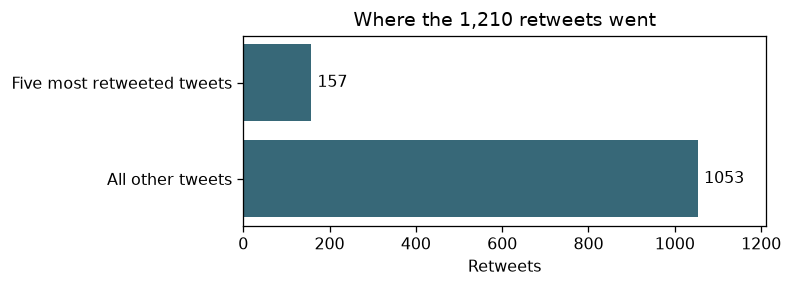

In [21]:
retweets = tweets["retweet_count"].fillna(0)
print("Retweet reach:", retweets.gt(0).sum(), "tweets retweeted;", retweets.sum(), "total retweets")
print("Top five share of retweets:", retweets.nlargest(5).sum() / retweets.sum())

top_five = retweets.nlargest(5).sum()
fig, ax = plt.subplots(figsize=(7, 2.6))
bars(ax, [("Five most retweeted tweets", top_five), ("All other tweets", retweets.sum() - top_five)],
     "Where the 1,210 retweets went", "Retweets")
ax.bar_label(ax.containers[0], fmt="%d", padding=4)
ax.margins(x=.15)
finish(fig)

# F1. Observation — A few posts account for a sizeable share of amplification.
# Evidence — The five most retweeted posts received 157 of 1,210 retweets (13.0%).
# Why it matters — Amplification can drive visible reputational exposure.
# Recommended action — Track widely shared issues alongside the urgency queue.
# Confidence and limits — Retweets are a snapshot and do not measure impressions.

### F2. Repeat handles contribute most tweets

Distinct handles: 7701 repeat handles: 3000 tweets by repeat handles: 9939


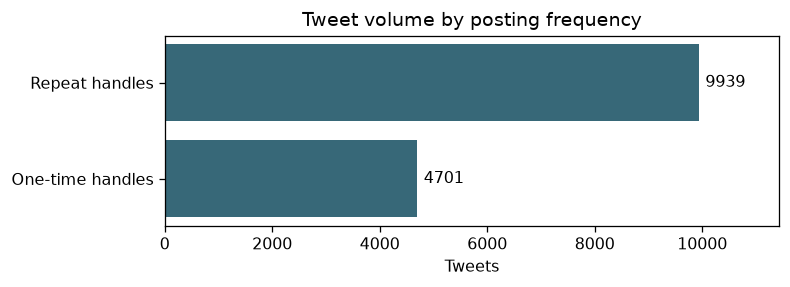

In [22]:
authors = tweets["name"].value_counts()
print("Distinct handles:", len(authors), "repeat handles:", authors.gt(1).sum(),
      "tweets by repeat handles:", authors[authors.gt(1)].sum())

post_totals = [("Repeat handles", authors[authors.gt(1)].sum()), ("One-time handles", authors.eq(1).sum())]
fig, ax = plt.subplots(figsize=(7, 2.6))
bars(ax, post_totals, "Tweet volume by posting frequency", "Tweets")
ax.bar_label(ax.containers[0], fmt="%d", padding=4)
ax.margins(x=.15)
finish(fig)

# F2. Observation — Repeat handles contribute most of the workload.
# Evidence — 3,000 repeat handles generated 9,939 of 14,640 tweets (67.9%).
# Why it matters — Agents may process multiple updates about the same issue.
# Recommended action — Group replies by handle and issue before assigning a case.
# Confidence and limits — A handle can report several issues or represent several people.

### F3. Label confidence varies by complaint reason

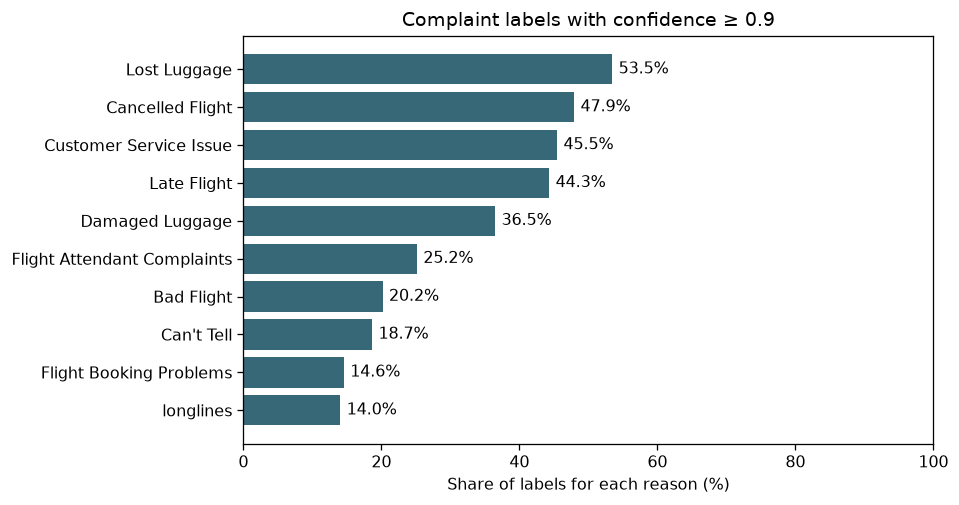

In [23]:
confidence_share = tweets.loc[negative].groupby("negativereason")["negativereason_confidence"].apply(
    lambda values: values.ge(.9).mean() * 100
).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars(ax, confidence_share.items(), "Complaint labels with confidence ≥ 0.9", "Share of labels for each reason (%)")
ax.set_xlim(0, 100)
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=4)
finish(fig)

# F3. Observation — Reason certainty varies substantially by complaint type.
# Evidence — 53.5% of lost-luggage labels reach 0.9 confidence versus 14.6%
# for flight booking problems and 14.0% for long lines.
# Why it matters — Booking and line tags are riskier for automatic routing.
# Recommended action — Review these tags and add clearer labeling examples.
# Confidence and limits — Agreement reflects annotator certainty, not correctness.